In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv


In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
# Load dataset
df = pd.read_csv(
    '/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv',
    sep=';'
)

df.columns = df.columns.str.strip()

# Separate features and target
X = df.drop(columns=['Target'])
y = df['Target']

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("Features Shape:", X.shape)

Dataset Loaded Successfully!
Dataset Shape: (4424, 37)
Features Shape: (4424, 36)


In [4]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3539, 36)
Testing Data: (885, 36)


In [5]:
# Create and train Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [6]:
# Calculate feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

                                   Feature  Importance
30     Curricular units 2nd sem (approved)    0.142283
31        Curricular units 2nd sem (grade)    0.109008
24     Curricular units 1st sem (approved)    0.091937
25        Curricular units 1st sem (grade)    0.059588
12                         Admission grade    0.043575
19                       Age at enrollment    0.040287
16                 Tuition fees up to date    0.038903
29  Curricular units 2nd sem (evaluations)    0.038200
23  Curricular units 1st sem (evaluations)    0.037504
6           Previous qualification (grade)    0.037498
3                                   Course    0.033886
11                     Father's occupation    0.028781
10                     Mother's occupation    0.026213
35                                     GDP    0.024465
33                       Unemployment rate    0.021617


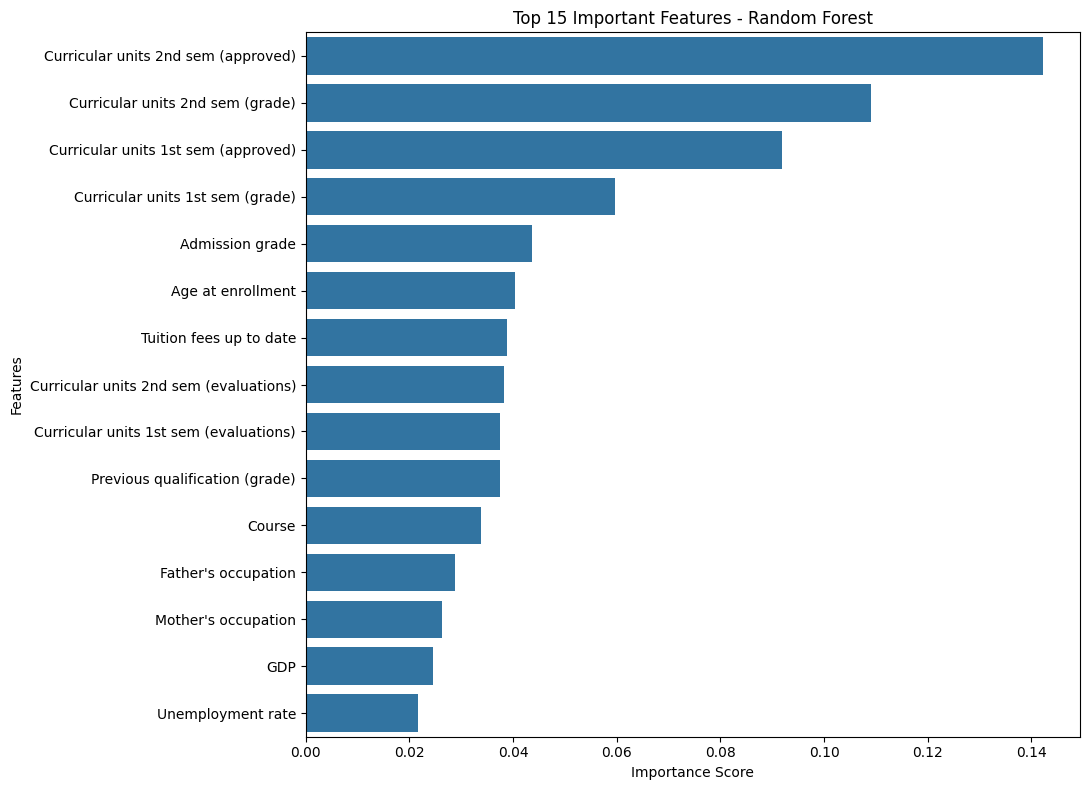

In [7]:
# Plot top 15 important features
plt.figure(figsize=(11, 8))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

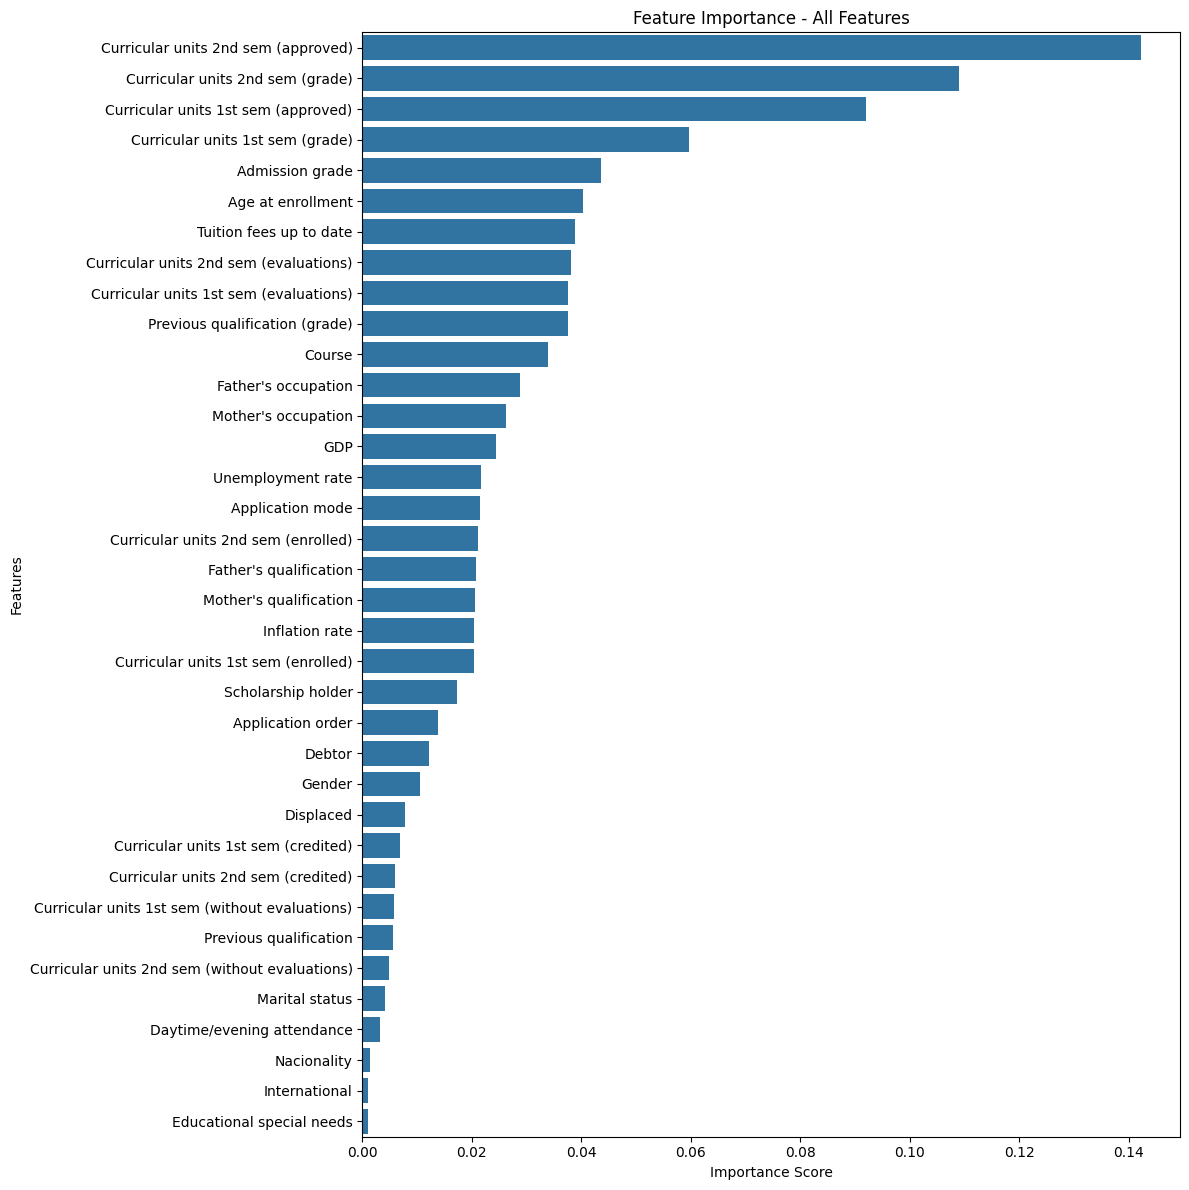

In [8]:
# Plot all feature importances
plt.figure(figsize=(12, 12))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - All Features')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [9]:
# Save feature importance results
feature_importance.to_csv(
    'feature_importance_results.csv',
    index=False
)

print("Feature Importance Results Saved Successfully!")

Feature Importance Results Saved Successfully!


In [10]:
# Generate feature importance summary
print("FEATURE IMPORTANCE SUMMARY")
print("---------------------------")

print("Total Features:", len(feature_importance))

print("\nTop 5 Most Important Features:")
print(feature_importance.head(5).to_string(index=False))

print("\nLeast 5 Important Features:")
print(feature_importance.tail(5).to_string(index=False))

FEATURE IMPORTANCE SUMMARY
---------------------------
Total Features: 36

Top 5 Most Important Features:
                            Feature  Importance
Curricular units 2nd sem (approved)    0.142283
   Curricular units 2nd sem (grade)    0.109008
Curricular units 1st sem (approved)    0.091937
   Curricular units 1st sem (grade)    0.059588
                    Admission grade    0.043575

Least 5 Important Features:
                   Feature  Importance
            Marital status    0.004154
Daytime/evening attendance    0.003167
               Nacionality    0.001470
             International    0.001082
 Educational special needs    0.001060
